# 04 - Krigeage et simulation (Turning Bands)

## Objectif de ce notebook

Créer une grille d'estimation, réaliser le krigeage de **Y.Pb** selon trois méthodes (Simple, Ordinaire, Universel), puis réaliser des
simulations conditionnelles par la méthode des **bandes tournantes** (Turning Bands Simulation).

*Ce notebook applique les techniques de krigeage et de simulation vues au TD7 (sections 1, 2, 4) au cas d'étude réel du TD8 (sections 3, 5 : superficie polluée et validation RMSE).*

##  Prérequis

Ce notebook reprend le contexte construit dans les notebooks 02 et 03 : base `db` avec la variable transformée **Y.Pb**, et le modèle de
variogramme ajusté `model_final` (Nugget + Sphérique, nugget=0.21,portée=0.60 km).

## Contenu

1. Création de la grille d'estimation (équivalent au voxet SKUA-Gocad)
2. Krigeage Simple (SK), Ordinaire (OK) et Universel (UK) + widget interactif de visualisation
3. Superficie des sols dépassant le seuil de pollution en Pb (question du TD8)
4. Simulation par bandes tournantes (TBS) — 4 réalisations + superficie polluée par réalisation
5. Krigeage (SK, OK) sur les points de validation — comparaison RMSE avec le Machine Learning (notebook 05)

## Sortie de ce notebook

Les cartes de krigeage et de simulation générées sur la grille `grid` peuvent être exportées dans `outputs/` pour analyse ultérieure.

## Rappel : recréer le contexte (notebooks 02 et 03)

Cette cellule reproduit rapidement les étapes essentielles des notebooks précédents afin que ce notebook puisse être exécuté de façon autonome.

In [67]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gstlearn as gl
import gstlearn.plot as gp
import ipywidgets as widgets
from ipywidgets import interactive_output
from sklearn.metrics import r2_score

# Ajout du chemin d'importation pour le module geostat_utils (remonte de jura/ jusqu'à src/)
sys.path.append(os.path.abspath(os.path.join("..", "..")))
import geostat_utils as gutils

# Reconstruction du contexte à l'aide de la fonction d'initialisation du module
data_jura, db, anam_hermite = gutils.preparer_db_gaussienne()

nombre_classe = 17
taille_classe = 0.291066
params_vario_omni = gl.VarioParam.createOmniDirection(
    nlag=nombre_classe, dlag=taille_classe, toldis=0.1
)
vario_exp_omni = gl.Vario(params_vario_omni)
err = vario_exp_omni.compute(db)

# ---- Modèle final retenu : Nugget + Sphérique (notebook 03) ----
model_final = gl.Model()
model_final.addCovFromParam(gl.ECov.NUGGET, sill=0.21 * 0.991462)
model_final.addCovFromParam(gl.ECov.SPHERICAL, range=0.60, sill=(1 - 0.21) * 0.991462)


## 1. Création de la grille d'estimation*(TD7)*

Une grille régulière de **100 × 100 cellules** est créée pour couvrir l'ensemble du domaine d'étude (équivalent au voxet dans SKUA-Gocad) :

- **NI** : 100 cellules selon X
- **NJ** : 100 cellules selon Y
- **Maille selon X** : 0.043 km *(= étendue X / 100 = 4.294 / 100, cf. notebook 03)*
- **Maille selon Y** : 0.051 km *(= étendue Y / 100 = 5.110 / 100, cf. notebook 03)*
- **Total** : 10 000 cellules

In [68]:
# ---- Création de la grille ----
grid = gutils.creer_grille(data_jura)

# Taille de maille récupérée directement depuis la grille déjà créée
maille_x, maille_y = grid.getDXs()

print(grid)



Data Base Grid Characteristics

Data Base Summary
-----------------
File is organized as a regular grid
Space dimension              = 2
Number of Columns            = 3
Total number of samples      = 10000

Grid characteristics:
---------------------
Origin :       0.626      0.580
Mesh   :       0.043      0.051
Number :         100        100

Variables
---------
Column = 0 - Name = rank - Locator = NA
Column = 1 - Name = x1 - Locator = x1
Column = 2 - Name = x2 - Locator = x2



## 2. Krigeage (SK, OK, UK) *(TD7)*

Le krigeage est appliqué sur la grille `grid` avec la variable **Y.Pb**. Le modèle utilisé est le modèle **Nugget + Sphérique** ajusté précédemment (notebook 03). Le Widget interactif d'affichage des cartes de krigeage permet de sélectionner la méthode (SK, OK, UK) et le type de carte (estimation ou variance/écart-type).

Les trois méthodes sont des estimateurs linéaires sans biais, de la forme générale :

$$
Z^*(\mathbf{x}) - m(\mathbf{x}) = \sum_{i=1}^{N} \lambda_i(\mathbf{x})\big(Z(\mathbf{x}_i) - m(\mathbf{x}_i)\big)
$$

où $\mathbf{x}=(x,y)$ est un point de la grille 2D, $m(\mathbf{x})$ le modèle de moyenne et $\lambda_i(\mathbf{x})$ les poids de krigeage. Elles ne diffèrent que par leur hypothèse sur $m(\mathbf{x})$ :

| Méthode | Hypothèse sur $m(\mathbf{x})$ | Système résolu |
|---|---|---|
| **SK** | constante et **connue** ($m=$ `mean_ypb`) | $\sum_j \lambda_j C_{ij} = C_{i\mathbf{x}}$ |
| **OK** | constante mais **inconnue**, estimée localement | idem + contrainte $\sum_i \lambda_i = 1$ (Lagrange $\mu$) |
| **UK** | tendance polynomiale $m(\mathbf{x})=\sum_k a_k f_k(\mathbf{x})$ (ici **drift d'ordre 1**, `gl.DriftIRF(order=1)` — tendance linéaire en X,Y) | idem OK, généralisé à $K{+}1$ contraintes de Lagrange |

La variance de krigeage associée s'écrit :

$$
\sigma_E^2(\mathbf{x}) = C(0) - \sum_{i=1}^N \lambda_i\, C(\mathbf{x}_i,\mathbf{x}) \;\; (\text{SK}), \qquad
\sigma_E^2(\mathbf{x}) = C(0) - \sum_{i=1}^N \lambda_i\, C(\mathbf{x}_i,\mathbf{x}) - \mu(\mathbf{x}) \;\; (\text{OK/UK})
$$

C'est cette variance qui est affichée dans le widget en mode "variance/écart-type".

In [69]:
gutils.krigeage_sk_ok_uk(dbin=db, dbout=grid, model_base=model_final, nom_variable="Y.Pb")
gutils.creer_widget_cartes_krigeage(dbout=grid, dbin=db, nom_variable="Y.Pb")

## 3. Superficie des sols dépassant le seuil de pollution (Pb > 90 ppm) *(TD8)*

**Énoncé (TD8)** : à l'aide du krigeage ordinaire de la teneur en Pb sur l'ensemble du domaine, déterminer la superficie des sols dépassant le seuil de 90 ppm.

**Démarche :**
1. Récupérer la carte de Pb estimée par krigeage ordinaire sur la grille (100×100 cellules)
2. Cette carte est dans l'espace gaussien (Y.Pb) → la retransformer en mg/kg avec l'anamorphose
3. Compter les cellules où Pb estimé > 90 mg/kg
4. Multiplier ce nombre de cellules par la surface d'une cellule pour obtenir la superficie polluée

In [70]:
# ---- Vérifier les colonnes disponibles dans la grille après krigeage ----
print(grid.getAllNames())

('rank', 'x1', 'x2', 'Kriging_simple.Y.Pb.estim', 'Kriging_simple.Y.Pb.stdev', 'Kriging_simple.Y.Pb.varz', 'Kriging_ordinaire.Y.Pb.estim', 'Kriging_ordinaire.Y.Pb.stdev', 'Kriging_ordinaire.Y.Pb.varz', 'Kriging_universel.Y.Pb.estim', 'Kriging_universel.Y.Pb.stdev')


In [71]:
# ----  récupérer la carte de Pb estimée par krigeage ordinaire (espace gaussien Y.Pb) ----
valeurs_gaussiennes = grid.getColumn("Kriging_ordinaire.Y.Pb.estim")
print(valeurs_gaussiennes[:10]) 

[0.07361361 0.07361361 0.07389799 0.08071665 0.09611808 0.11942526
 0.14996043 0.18704471 0.2304182  0.27996647]


In [72]:
# ----retransformer les valeurs gaussiennes en mg/kg avec l'anamorphose (notebook 02) ----
valeurs_pb = anam_hermite.gaussianToRawVector(valeurs_gaussiennes)
valeurs_pb = np.array(valeurs_pb)  # conversion en tableau numpy classique
print(valeurs_pb[:10])

[46.53919776 46.53919776 46.54422773 46.6650863  46.93987412 47.36050495
 47.92042403 48.61415263 49.44502596 50.42050966]


In [73]:
def compter_cellules_polluees(valeurs_pb, seuil):
    """Compte le nombre de cellules de la grille dont la concentration
    estimée dépasse un seuil de pollution donné.

    Paramètres
    ----------
    valeurs_pb : array-like
        Concentrations de Pb estimées sur la grille, en échelle brute (mg/kg).
    seuil : float
        Seuil de pollution (mg/kg) au-delà duquel une cellule est jugée polluée.

    Retourne
    --------
    tuple : (masque_pollue, nb_cellules_polluees)
        masque_pollue : np.ndarray de bool, True pour les cellules polluées.
        nb_cellules_polluees : int, nombre total de cellules polluées.
    """
    zone_polluee = valeurs_pb > seuil
    nb_cellules_polluees = zone_polluee.sum()
    return zone_polluee, nb_cellules_polluees

def calculer_surface(nb_cellules, surface_une_cellule):
    """Calcule la surface totale (km²) à partir du nombre de cellules et de la surface d'une cellule."""
    return nb_cellules * surface_une_cellule

surface_cellule = maille_x * maille_y

# ---- Utilisation ----
seuil_pollution = 90  # mg/kg
zone_polluee, nb_cellules_polluees = compter_cellules_polluees(valeurs_pb, seuil_pollution)
surface_polluee = calculer_surface(nb_cellules_polluees, surface_cellule)
proportion_polluee = nb_cellules_polluees / len(valeurs_pb) * 100

print(f"Nombre de cellules dépassant {seuil_pollution} mg/kg : {nb_cellules_polluees}")
print(f"Sur un total de : {len(valeurs_pb)} cellules")
print(f"Superficie polluée estimée : {surface_polluee:.3f} km²")
print(f"Proportion polluée : {proportion_polluee:.1f} %")

Nombre de cellules dépassant 90 mg/kg : 10
Sur un total de : 10000 cellules
Superficie polluée estimée : 0.022 km²
Proportion polluée : 0.1 %


In [74]:
# ---- Reshape en grille 2D (100x100) pour l'affichage cartographique ----
carte_pb_krigeage = valeurs_pb.reshape(100, 100)
carte_zone_polluee_krigeage = zone_polluee.reshape(100, 100)

### Visualisation de la zone polluée
Carte de la concentration en Pb estimée par krigeage ordinaire, avec le contour de la zone dépassant le seuil de 90 mg/kg surligné.

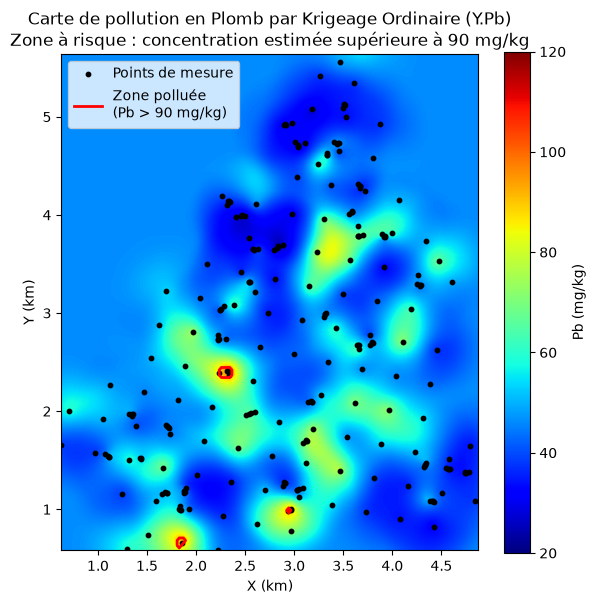

In [75]:
limites_domaine = grid.getExtremas()
etendue_carte = [limites_domaine[0][0], limites_domaine[0][1], limites_domaine[1][0], limites_domaine[1][1]]

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(carte_pb_krigeage, origin="lower", cmap="jet", vmin=20, vmax=120,
                extent=etendue_carte, interpolation="bilinear")
plt.colorbar(im, ax=ax, label="Pb (mg/kg)")
ax.scatter(data_jura["X"], data_jura["Y"], c="black", s=10, label="Points de mesure")
ax.contour(carte_zone_polluee_krigeage, levels=[0.5], colors="red", linewidths=2, extent=etendue_carte)
ax.plot([], [], color="red", linewidth=2, label=f"Zone polluée \n(Pb > {seuil_pollution} mg/kg)")  # ligne fictive juste pour la légende

ax.set_title("Carte de pollution en Plomb par Krigeage Ordinaire (Y.Pb)\nZone à risque : concentration estimée supérieure à 90 mg/kg")
ax.set_xlabel("X (km)")
ax.set_ylabel("Y (km)")
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(etendue_carte[0], etendue_carte[1])
ax.set_ylim(etendue_carte[2], etendue_carte[3])
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 4. Turning Bands Simulation de Pb *(méthode alternative au SGS du TD7)*

### Pourquoi simuler après avoir krigé ?

Le krigeage ne donne que l'**espérance conditionnelle** : une carte lisse qui **sous-estime la variabilité spatiale** (Caumon, *7.3*). Une simulation produit à l'inverse une **réalisation** qui respecte la pdf de la variable ($\mathcal{N}(0,1)$ ici, `Y.Pb` étant normalisée) et le variogramme  d'où l'intérêt de générer **plusieurs réalisations** équiprobables plutôt qu'une seule carte.

Les bandes tournantes (TBS) sont l'une des méthodes de simulation de variables continues (Caumon, *7.2*), aux côtés du SGS.

### Mise en œuvre

`gl.simtub()` génère **4 réalisations** avec **1000 bandes** et `seed=12345` (reproductibilité), sur le modèle Nugget + Sphérique de moyenne `mean_ypb`.

Les simulations sont affichées dans l'espace gaussien (vmin=-3, vmax=3) ; une **back-transformation** (notebook 02) serait nécessaire pour revenir aux valeurs réelles de Pb.

In [76]:
# ---- Simulation par bandes tournantes (4 réalisations) + widget interactif de visualisation ----# ---- Simulation par bandes tournantes (4 réalisations) + widget interactif de visualisation ----
prefixe = gutils.simulation_bandes_tournantes(dbin=db, dbout=grid, model_base=model_final, nom_variable="Y.Pb")
gutils.creer_widget_realisations(dbout=grid, dbin=db, prefixe=prefixe, nom_variable="Y.Pb")

In [77]:
# ----extraire et retransformer la 1ère réalisation (S1) en mg/kg ----
simulation1_gaussienne = grid.getColumn("YPbSimu.Y.Pb.S1")
simulation1_pb_reel = np.array(anam_hermite.gaussianToRawVector(simulation1_gaussienne))
print(simulation1_pb_reel[:10])

[44.64616788 53.74722371 39.92199997 56.64551853 54.66209923 58.03982868
 66.92725892 67.93880803 88.13477385 71.34344241]


In [78]:
# ---- Retransformer les 4 réalisations en mg/kg (espace brut) et les ajouter comme nouvelles colonnes ----
prefixe_simulations_reelles = gutils.ajouter_colonnes_reelles_simulation(grid, "YPbSimu", anam_hermite, nb_simulations=4)
print([n for n in grid.getAllNames() if prefixe_simulations_reelles in n])

['YPbSimu_reel.S1', 'YPbSimu_reel.S2', 'YPbSimu_reel.S3', 'YPbSimu_reel.S4']


In [79]:
# ---- Widget interactif : visualiser chaque réalisation (échelle brute mg/kg) avec le contour de la zone polluée ----
gutils.creer_widget_realisations_avec_seuil(dbout=grid, dbin=db, prefixe=prefixe_simulations_reelles, nom_variable="Pb (mg/kg)", seuil=90)

In [80]:
print("Surfaces polluées par réalisation (Pb > 90 mg/kg) :\n")
surfaces_sim = {}
for i in range(1, 5):
    valeurs_sim = np.array(grid.getColumn(f"{prefixe_simulations_reelles}.S{i}"))
    _, nb_cell_sim = compter_cellules_polluees(valeurs_sim, seuil_pollution)
    surface_sim = calculer_surface(nb_cell_sim, surface_cellule)
    surfaces_sim[i] = surface_sim
    print(f"  Réalisation {i} : {surface_sim:.4f} km²")

print(f"\nMoyenne  : {np.mean(list(surfaces_sim.values())):.4f} km²")
print(f"Écart-type : {np.std(list(surfaces_sim.values())):.4f} km²")

Surfaces polluées par réalisation (Pb > 90 mg/kg) :

  Réalisation 1 : 0.9633 km²
  Réalisation 2 : 0.9150 km²
  Réalisation 3 : 1.2814 km²
  Réalisation 4 : 0.5135 km²

Moyenne  : 0.9183 km²
Écart-type : 0.2729 km²


## 5. Krigeage (SK, OK) sur `df_validation` erreur RMS et comparaison avec le Machine Learning *(TD8)*

**Pourquoi krigeage directement sur les 100 points de validation, plutôt que sur toute la grille ?** Le krigeage sur la grille (partie précédente) sert à produire des cartes visuelles sur tout le domaine. Ici, l'objectif est différent : obtenir une estimation ponctuelle exactement aux positions des 100 points de `df_validation`, pour pouvoir calculer un RMSE directement comparable à celui obtenu par Random Forest, XGBoost et CatBoost (notebook 05) — condition indispensable pour une comparaison ML vs krigeage non biaisée.

### Critère de comparaison : RMSE

$$
\mathrm{RMSE} = \sqrt{\frac{1}{N_v}\sum_{i=1}^{N_v} \big(Z(\mathbf{x}_i) - Z^*(\mathbf{x}_i)\big)^2}
$$

Le RMSE mesure l'erreur moyenne entre valeurs réelles et estimées, en pénalisant davantage les grosses erreurs (Chai & Draxler, *"Root mean square error (RMSE) or mean absolute error (MAE)? – Arguments against avoiding RMSE in the literature"*). C'est ce critère, calculé en mg/kg après back-transformation, qui permet la comparaison avec le ML (notebook 05).

In [81]:
"""
Krigeage (SK, OK) sur les 100 points de df_validation.
"""

df_validation = pd.read_csv("../../../data/JuraValidationData.csv", sep=";")

def calcul_rmse(y_reel, y_estime):
    """Calcule la racine de l'erreur quadratique moyenne (RMSE) entre les
    valeurs réelles et les valeurs estimées.

    Même formule que dans le notebook 05-validation-croisee.ipynb (calcul_rmse),
    dupliquée ici pour que ce notebook reste exécutable indépendamment.

    Paramètres
    ----------
    y_reel : array-like
        Valeurs réelles observées (ex. Pb mesuré, mg/kg).
    y_estime : array-like
        Valeurs estimées par le modèle (ex. Pb krigé, mg/kg).

    Retourne
    --------
    float
        La RMSE, dans la même unité que y_reel/y_estime.
    """
    return np.sqrt(np.nanmean((np.asarray(y_estime) - np.asarray(y_reel)) ** 2))

# 1. Créer une Db gstlearn à partir des coordonnées de df_validation
db_validation = gl.Db.create()
db_validation["x1"] = df_validation["X"].values
db_validation["x2"] = df_validation["Y"].values
db_validation.setLocators(["x1", "x2"], gl.ELoc.X)

voisinage_krigeage = gl.NeighUnique.create()
moyenne_ypb = np.mean(db.getColumn("Y.Pb"))

# Étape 2 : Krigeage Simple — ceci est le MODÈLE, garde model_sk
model_sk = model_final.clone()
model_sk.setMean(moyenne_ypb)
gl.kriging(dbin=db, dbout=db_validation, model=model_sk, neigh=voisinage_krigeage,
           flag_est=True, flag_varz=True, namconv=gl.NamingConvention("SK"))

# Étape 3 : Krigeage Ordinaire — ceci est le MODÈLE, garde model_ok
model_ok = model_final.clone()
model_ok.addDrift(gl.DriftM())
gl.kriging(dbin=db, dbout=db_validation, model=model_ok, neigh=voisinage_krigeage,
           flag_est=True, flag_varz=True, namconv=gl.NamingConvention("OK"))

print("Colonnes créées :", db_validation.getAllNames())

# Étape 4 : ICI seulement, ce sont les vraies ESTIMATIONS gaussiennes
estim_ok_gaussien = np.array(db_validation["OK.Y.Pb.estim"])
estim_sk_gaussien = np.array(db_validation["SK.Y.Pb.estim"])
print("Identiques dès l'espace gaussien ?", np.array_equal(estim_ok_gaussien, estim_sk_gaussien))

# 5. Back-transformation gaussien -> Pb réel (gaussianToRawVector)
pred_ok_pb = np.array(anam_hermite.gaussianToRawVector(estim_ok_gaussien))
pred_sk_pb = np.array(anam_hermite.gaussianToRawVector(estim_sk_gaussien))

# 6. RMSE
rmse_ok = calcul_rmse(df_validation["Pb"], pred_ok_pb)
rmse_sk = calcul_rmse(df_validation["Pb"], pred_sk_pb)

print(f"RMSE Krigeage Ordinaire : {rmse_ok:.3f}")
print(f"RMSE Krigeage Simple    : {rmse_sk:.3f}")


Colonnes créées : ('x1', 'x2', 'SK.Y.Pb.estim', 'SK.Y.Pb.stdev', 'SK.Y.Pb.varz', 'OK.Y.Pb.estim', 'OK.Y.Pb.stdev', 'OK.Y.Pb.varz')
Identiques dès l'espace gaussien ? False
RMSE Krigeage Ordinaire : 38.858
RMSE Krigeage Simple    : 38.927


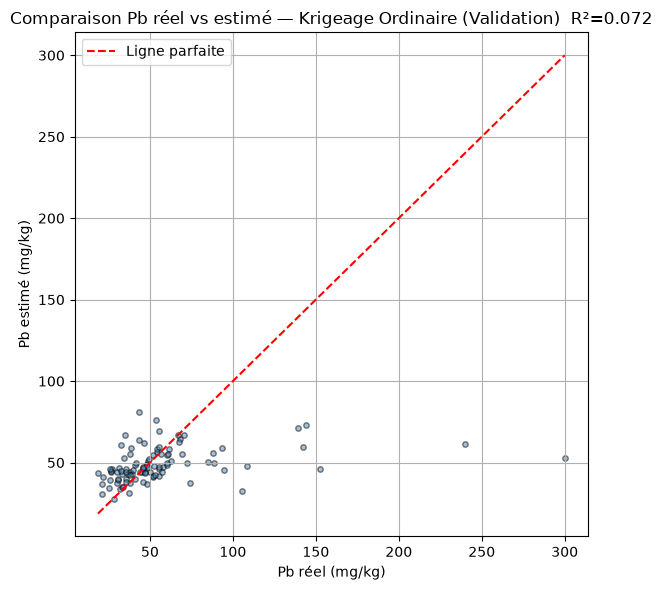

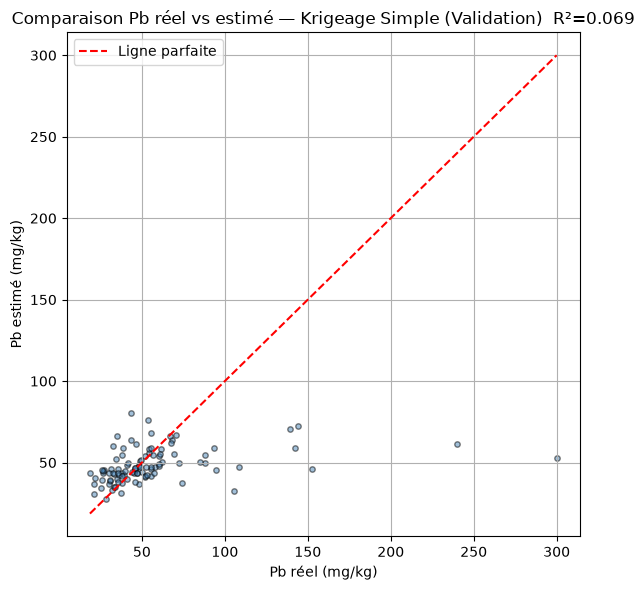

In [83]:
def afficher_estim_vs_reel(y_reel, y_estime, nom_modele, split="Validation"):
    
    """Trace le nuage de points des valeurs réelles vs estimées (Pb, mg/kg),
    avec la ligne de prédiction parfaite (y = x) pour évaluer visuellement
    la qualité d'un modèle d'estimation (krigeage ou ML).

    Paramètres
    ----------
    y_reel : array-like
        Valeurs réelles observées.
    y_estime : array-like
        Valeurs estimées par le modèle.
    nom_modele : str
        Nom du modèle affiché dans le titre du graphique (ex. "Krigeage Ordinaire").
    split : str, optionnel
        Nom du jeu de données affiché dans le titre (ex. "Validation", "Test").
        Par défaut "Validation".
    """
    r2 = r2_score(y_reel, y_estime)
    plt.figure(figsize=(6, 6))
    plt.scatter(y_reel, y_estime, alpha=0.5, edgecolor="k", s=15, color="steelblue")
    vmin, vmax = min(y_reel.min(), y_estime.min()), max(y_reel.max(), y_estime.max())
    plt.plot([vmin, vmax], [vmin, vmax], "r--", label="Ligne parfaite")
    plt.xlabel("Pb réel (mg/kg)")
    plt.ylabel("Pb estimé (mg/kg)")
    plt.title(f"Comparaison Pb réel vs estimé — {nom_modele} ({split})  R²={r2:.3f}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

afficher_estim_vs_reel(df_validation["Pb"], pred_ok_pb, "Krigeage Ordinaire")
afficher_estim_vs_reel(df_validation["Pb"], pred_sk_pb, "Krigeage Simple")
# 7. Sauvegarde pour le notebook 05 (comparaison krigeage vs ML)
gutils.sauvegarder_resultats_krigeage(rmse_ok, rmse_sk, pred_ok_pb, pred_sk_pb)

## Conclusion

Le krigeage (SK, OK, UK) et la simulation TBS estiment tous deux la distribution spatiale du Pb, mais avec des résultats très différents pour la superficie polluée : **0.022 km²** selon le krigeage ordinaire, contre une moyenne de **0.918 km²** sur les 4 simulations.Le krigeage lisse la carte et sous-estime fortement les zones à risque.

Sur les 100 points de validation, le RMSE est de **38.858 mg/kg (OK)** et **38.927 mg/kg (SK)**, soit ~70 % de la teneur moyenne en Pb : une erreur élevée qui, combinée à la sous-estimation de la superficie, montre que **le krigeage seul n'est pas suffisant** pour délimiter une zone de pollution, la simulation offre une évaluation du risque plus complète.